# Daily Rainfall Forecasting in West Java with LSTM (Sequential Data)



## 0. Setup
Imports, configuration, fixed random seed (reproducibility) and device.

In [ ]:
import os, glob, random, time, copy, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})

In [ ]:
# ----------------------------- Configuration -----------------------------
SEED       = 42
SEEDS      = [42, 43, 44]     # every model variant is trained with 3 seeds (averages are more reliable than one run)
WINDOW     = 30               # sliding window length: use the previous 30 days ...
HORIZON    = 1                # ... to predict the next day
TRAIN_FRAC = 0.70             # chronological split: first 70% of the days -> train
VAL_FRAC   = 0.15             # next 15% -> validation, last 15% -> test
BATCH_SIZE = 64
MAX_EPOCHS = 100
PATIENCE   = 15               # early stopping: stop when validation loss does not improve for 15 epochs
HIDDEN     = 64               # hidden units of every recurrent layer
LR         = 3e-3
DEBUG      = False            # True -> 2 epochs and 1 seed, only to check that the code runs

# --- Dataset location (set ONE of these) ---
# Local runtime (own PC/GPU): put the ZIP next to this notebook, or write its full path here, e.g. r'C:\Users\name\Downloads\Daily_Rainfall....zip'
# Colab runtime: leave LOCAL_ZIP_PATH empty; the ZIP is read from Google Drive (ZIP_PATH below).
LOCAL_ZIP_PATH = ''
ZIP_PATH     = '/content/drive/MyDrive/Colab Notebooks/Daily_Rainfall_Observations_from_460_Stations_and.zip'
EXTRACT_PATH = os.path.join(os.getcwd(), 'rainfall_data')      # works on both Colab and a local runtime

if DEBUG:
    MAX_EPOCHS, SEEDS = 2, [42]

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## 1. Data Preparation
### 1.1 Load the dataset
The ZIP file is read from Google Drive and extracted once. The rainfall file `01_Data-Ch-Jabar-2020-2025.xlsx`
(sheet `DATA`) is a **wide matrix**: one row per day (`Date` column) and one column per rainfall station (460 stations).

In [ ]:
# 1) Find the ZIP: explicit local path -> Google Drive (Colab) -> common local folders
candidates = []
if LOCAL_ZIP_PATH:
    candidates.append(LOCAL_ZIP_PATH)
else:
    try:                                              # only works on a Colab-hosted runtime
        from google.colab import drive
        drive.mount('/content/drive')
        candidates += [ZIP_PATH] + glob.glob('/content/drive/MyDrive/*Rainfall*.zip') + glob.glob('/content/drive/MyDrive/*/*Rainfall*.zip')
    except Exception as e:
        print('Google Drive not available (local runtime) -> searching local folders.')
    home = os.path.expanduser('~')
    for folder in (os.getcwd(), os.path.join(home, 'Downloads'), os.path.join(home, 'Documents'), os.path.join(home, 'Desktop')):
        candidates += glob.glob(os.path.join(folder, '*Rainfall*.zip'))
found = [c for c in candidates if os.path.exists(c)]
if not found:
    raise FileNotFoundError('Dataset ZIP not found. Put it next to the notebook or set LOCAL_ZIP_PATH in the configuration cell.')
ZIP_PATH = found[0]
print('ZIP file:', ZIP_PATH)

if not glob.glob(os.path.join(EXTRACT_PATH, '**', '01_Data-Ch-Jabar*.xlsx'), recursive=True):
    os.makedirs(EXTRACT_PATH, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(EXTRACT_PATH)
    print('Extracted to', EXTRACT_PATH)

XLSX = glob.glob(os.path.join(EXTRACT_PATH, '**', '01_Data-Ch-Jabar*.xlsx'), recursive=True)[0]
raw = pd.read_excel(XLSX, sheet_name='DATA')
print('Rainfall file :', os.path.basename(XLSX))
print('Raw shape     :', raw.shape, '(rows = days, columns = Date + stations)')
display(raw.iloc[:5, :6])

Google Drive not available (local runtime) -> searching local folders.
ZIP file: C:\Users\binta\Downloads\Daily Rainfall Observations from 460 Stations and.zip
Rainfall file : 01_Data-Ch-Jabar-2020-2025.xlsx
Raw shape     : (2192, 461) (rows = days, columns = Date + stations)


,Date,Ciriung,BP3K Jonggol,Dayeuh/Sukanagara,Klapanunggal,Situ Tungilis
0,2020-01-01,45.0,0.0,55.0,55.0,63.0
1,2020-01-02,106.0,7.0,40.0,36.0,38.0
2,2020-01-03,0.0,0.0,0.0,0.0,0.0
3,2020-01-04,0.0,0.0,38.0,45.0,26.0
4,2020-01-05,26.0,0.0,0.0,0.0,0.0


### 1.2 Inspect and clean
Checks performed:
* **Dates:** convert to `datetime`, sort, and verify there are no duplicate or skipped days (a time series must be regularly spaced).
* **Data types:** a few station columns contain the text code `R` instead of a number; these entries are not valid rainfall values and are converted to missing values (`NaN`).
* **Missing values:** count them per station.

Period          : 2020-01-01 to 2025-12-31 (2192 days)
Duplicate dates : 0 | skipped dates: 0
Non-numeric entries converted to NaN: 739 | distinct values: ['R'] | in 7 stations
Stations: 460 | overall missing: 2.19%
Negative values: 0 | max value (mm/day): 456.0


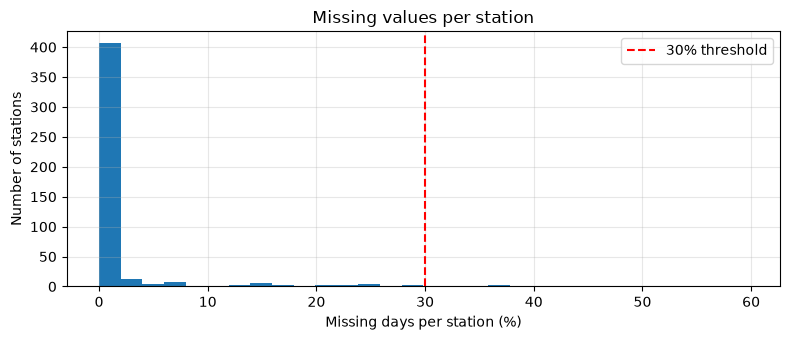

In [ ]:
raw['Date'] = pd.to_datetime(raw['Date'])
raw = raw.sort_values('Date').set_index('Date')

full_range = pd.date_range(raw.index.min(), raw.index.max(), freq='D')
print(f'Period          : {raw.index.min().date()} to {raw.index.max().date()} ({len(raw)} days)')
print('Duplicate dates :', raw.index.duplicated().sum(), '| skipped dates:', len(full_range.difference(raw.index)))

# Convert everything to numbers; non-numeric entries become NaN
num = raw.apply(pd.to_numeric, errors='coerce')
is_text = num.isna() & raw.notna()                     # cells that hold something, but not a number
text_values = raw[is_text].stack().dropna()
print('Non-numeric entries converted to NaN:', int(is_text.values.sum()), '| distinct values:', text_values.unique().tolist(),
      '| in', int(is_text.any().sum()), 'stations')

n_stations = num.shape[1]
miss_frac = num.isna().mean()                       # fraction of missing days per station
print(f'Stations: {n_stations} | overall missing: {num.isna().values.mean():.2%}')
print('Negative values:', int((num < 0).sum().sum()), '| max value (mm/day):', num.max().max())

plt.figure(figsize=(8, 3.5))
plt.hist(miss_frac * 100, bins=30, color='tab:blue')
plt.axvline(30, color='red', ls='--', label='30% threshold')
plt.xlabel('Missing days per station (%)'); plt.ylabel('Number of stations'); plt.title('Missing values per station')
plt.legend(); plt.tight_layout(); plt.show()

### 1.3 Handle missing values and build the target series
Modelling 460 separate series is not necessary for this question, and a single station is a poor target (the median station has 0 mm on about half of the days).
Therefore the target is the **province-wide mean daily rainfall (mm/day)**, built in two steps:

1. **Drop unreliable stations:** stations with more than 30% missing days are removed (the dataset authors also flag them).
2. **Average over the stations that reported on each day** (`skipna=True`). Because hundreds of stations report every day, a day is almost never missing, so no artificial values have to be invented (no leakage from the future).

A safety net (time interpolation) is applied only if some day would still be missing.

In [ ]:
keep = miss_frac[miss_frac <= 0.30].index
dropped = miss_frac[miss_frac > 0.30].index
print(f'Stations kept: {len(keep)} | dropped (>30% missing): {len(dropped)} -> {list(dropped)}')

n_reporting = num[keep].notna().sum(axis=1)         # how many stations contributed each day
series = num[keep].mean(axis=1, skipna=True).rename('rain_mm')

print('Stations reporting per day: min', n_reporting.min(), '| median', int(n_reporting.median()), '| max', n_reporting.max())
print('Days still missing after averaging:', int(series.isna().sum()))
if series.isna().any():                              # safety net (not triggered for this dataset)
    series = series.interpolate(method='time', limit_direction='both')
assert series.isna().sum() == 0

display(series.describe().round(2).to_frame().T)

Stations kept: 453 | dropped (>30% missing): 7 -> ['Kuningan', 'Ambit', 'Pamengkang', 'Karang Kendal', 'Bendung Ampera', 'Buah Dua', 'Cimahi']
Stations reporting per day: min 257 | median 451 | max 453
Days still missing after averaging: 0


,count,mean,std,min,25%,50%,75%,max
rain_mm,2192.0,7.65,6.84,0.0,2.03,6.19,11.28,47.13


### 1.4 Plot the data
Three views: (a) the daily series with a 30-day moving average, (b) the average rainfall per calendar month (seasonality: wet season ≈ Nov–Mar, dry season ≈ Jun–Sep),
(c) the autocorrelation, which shows how strongly today's rainfall is related to the previous days (this helps to justify the window length).

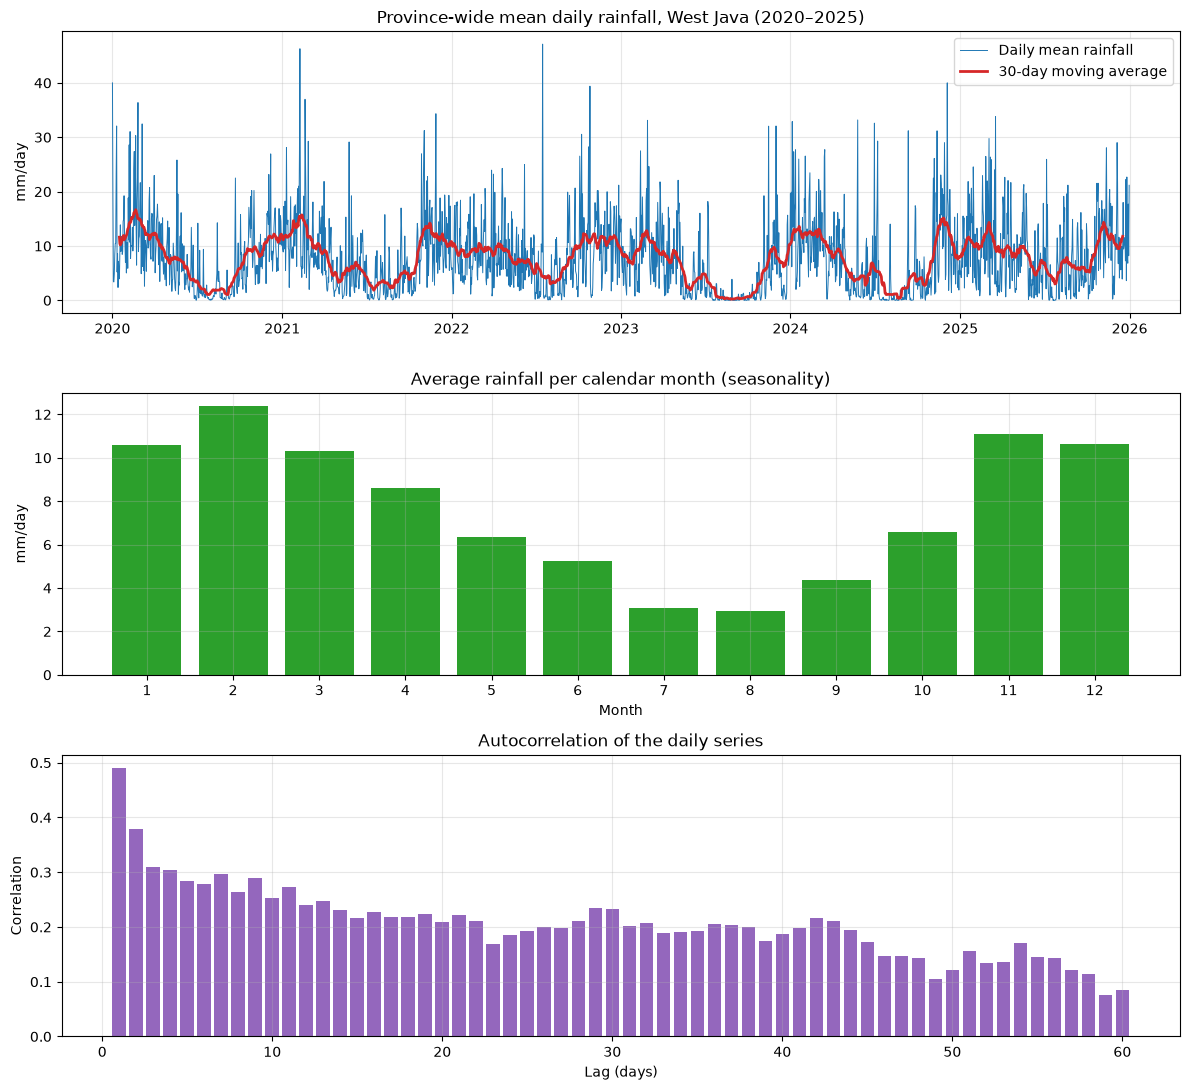

Autocorrelation: lag 1 = 0.49, lag 2 = 0.38, lag 7 = 0.30


In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(12, 11))

ax[0].plot(series.index, series.values, lw=0.7, color='tab:blue', label='Daily mean rainfall')
ax[0].plot(series.rolling(30, center=True).mean(), lw=2, color='tab:red', label='30-day moving average')
ax[0].set(title='Province-wide mean daily rainfall, West Java (2020–2025)', ylabel='mm/day'); ax[0].legend()

monthly = series.groupby(series.index.month).mean()
ax[1].bar(monthly.index, monthly.values, color='tab:green')
ax[1].set(title='Average rainfall per calendar month (seasonality)', xlabel='Month', ylabel='mm/day', xticks=range(1, 13))

lags = range(1, 61)
acf = [series.autocorr(l) for l in lags]
ax[2].bar(lags, acf, color='tab:purple')
ax[2].set(title='Autocorrelation of the daily series', xlabel='Lag (days)', ylabel='Correlation')
plt.tight_layout(); plt.show()

print(f'Autocorrelation: lag 1 = {acf[0]:.2f}, lag 2 = {acf[1]:.2f}, lag 7 = {acf[6]:.2f}')

### 1.5 Chronological split (70 / 15 / 15)
For a time series the split must follow time: **train = earliest days, validation = next, test = latest**. A random split would let the model "see the future" and give over-optimistic results.
The scaler (min–max) is fitted **only on the training period** and then applied to all periods, so no information from validation/test leaks into training.

,Start,End,Days
Train,2020-01-01,2024-03-13,1534
Validation,2024-03-14,2025-02-05,329
Test,2025-02-06,2025-12-31,329


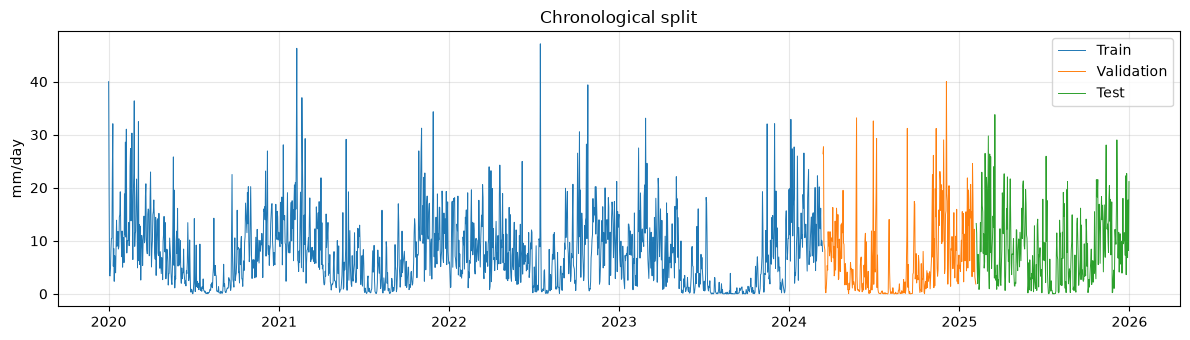

Train min/max used for scaling: 0.00 / 47.13 mm/day


In [ ]:
n = len(series)
i_train = int(n * TRAIN_FRAC)
i_val   = int(n * (TRAIN_FRAC + VAL_FRAC))

split_table = pd.DataFrame({
    'Start': [series.index[0], series.index[i_train], series.index[i_val]],
    'End':   [series.index[i_train - 1], series.index[i_val - 1], series.index[-1]],
    'Days':  [i_train, i_val - i_train, n - i_val],
}, index=['Train', 'Validation', 'Test'])
split_table['Start'] = split_table['Start'].dt.date; split_table['End'] = split_table['End'].dt.date
display(split_table)

plt.figure(figsize=(12, 3.5))
plt.plot(series.index[:i_train], series.values[:i_train], lw=0.7, label='Train')
plt.plot(series.index[i_train:i_val], series.values[i_train:i_val], lw=0.7, label='Validation')
plt.plot(series.index[i_val:], series.values[i_val:], lw=0.7, label='Test')
plt.title('Chronological split'); plt.ylabel('mm/day'); plt.legend(); plt.tight_layout(); plt.show()

scaler = MinMaxScaler()
scaler.fit(series.values[:i_train].reshape(-1, 1))                       # fitted on TRAIN only
scaled = scaler.transform(series.values.reshape(-1, 1)).ravel()
print(f'Train min/max used for scaling: {scaler.data_min_[0]:.2f} / {scaler.data_max_[0]:.2f} mm/day')

### 1.6 Sliding window
Each sample is a window of the previous `WINDOW` = 30 days (input `X`, shape `[30, 1]`) and the rainfall of the next day (target `y`).
A sample belongs to the split of its **target day**. Inputs of the first validation/test samples reach back into the previous period; that is legitimate, because those are past observations.

In [ ]:
def make_windows(values, window):
    X, y = [], []
    for t in range(window, len(values)):
        X.append(values[t - window:t]); y.append(values[t])
    return np.array(X, dtype=np.float32)[..., None], np.array(y, dtype=np.float32)

X_all, y_all = make_windows(scaled, WINDOW)
target_pos = np.arange(WINDOW, n)                  # position (day index) of each target

masks = {'train': target_pos < i_train,
         'val':   (target_pos >= i_train) & (target_pos < i_val),
         'test':  target_pos >= i_val}
data = {k: (X_all[m], y_all[m]) for k, m in masks.items()}
target_dates = {k: series.index[target_pos[m]] for k, m in masks.items()}
y_true = {k: series.values[target_pos[m]] for k, m in masks.items()}           # real values in mm/day

shape_table = pd.DataFrame({k: {'X shape': data[k][0].shape, 'y shape': data[k][1].shape,
                                'First target day': target_dates[k][0].date()} for k in data}).T
display(shape_table)

def make_loader(split, shuffle):
    g = torch.Generator(); g.manual_seed(SEED)
    X, y = data[split]
    return DataLoader(TensorDataset(torch.tensor(X), torch.tensor(y)), batch_size=BATCH_SIZE, shuffle=shuffle, generator=g)

train_loader = make_loader('train', True)

,X shape,y shape,First target day
train,"(1504, 30, 1)","(1504,)",2020-01-31
val,"(329, 30, 1)","(329,)",2024-03-14
test,"(329, 30, 1)","(329,)",2025-02-06


## 2. Baseline: Naive Forecast

The naive forecast predicts that **tomorrow's rainfall equals today's**: `ŷ(t) = y(t−1)`. It needs no training and is the minimum that any learned model must beat.
It is evaluated on exactly the same test days (and the same real values in mm/day) as the LSTM models.
As additional context, a second reference is shown: always predicting the **training-period mean** (a constant "climatology" forecast).

In [ ]:
def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))
def mae(y, p):  return float(mean_absolute_error(y, p))

naive_pred = {k: series.values[target_pos[m] - 1] for k, m in masks.items()}      # value of the previous day
mean_pred  = {k: np.full(m.sum(), series.values[:i_train].mean()) for k, m in masks.items()}

baseline_table = pd.DataFrame({
    'Naive (tomorrow = today)': {f'{s} {mt}': f(y_true[s], naive_pred[s]) for s in ('val', 'test') for mt, f in (('RMSE', rmse), ('MAE', mae))},
    'Train-mean (reference)':   {f'{s} {mt}': f(y_true[s], mean_pred[s])  for s in ('val', 'test') for mt, f in (('RMSE', rmse), ('MAE', mae))},
}).T
display(baseline_table.round(3))
naive_rmse_test, naive_mae_test = rmse(y_true['test'], naive_pred['test']), mae(y_true['test'], naive_pred['test'])
print(f'Naive baseline on the test set -> RMSE = {naive_rmse_test:.3f} mm/day, MAE = {naive_mae_test:.3f} mm/day')

,val RMSE,val MAE,test RMSE,test MAE
Naive (tomorrow = today),7.328,4.571,7.698,5.572
Train-mean (reference),7.343,5.983,6.864,5.413


Naive baseline on the test set -> RMSE = 7.698 mm/day, MAE = 5.572 mm/day


## 3. LSTM Model

### 3.1 How an LSTM works (penjelasan singkat)

LSTM (*Long Short-Term Memory*) adalah jenis RNN yang dirancang agar dapat mengingat informasi jangka panjang dan tidak mudah mengalami *vanishing gradient*.
Pada setiap langkah waktu *t*, sel menerima input **x<sub>t</sub>** (curah hujan hari itu), keadaan tersembunyi sebelumnya **h<sub>t−1</sub>**, dan keadaan sel sebelumnya **C<sub>t−1</sub>**.

| Komponen | Rumus | Fungsi |
|---|---|---|
| **Cell state (C<sub>t</sub>)** | C<sub>t</sub> = f<sub>t</sub> ⊙ C<sub>t−1</sub> + i<sub>t</sub> ⊙ C̃<sub>t</sub> | "Jalur memori" utama yang membawa informasi jangka panjang sepanjang deret. Hanya diubah lewat operasi sederhana (kali dan tambah), sehingga gradien dapat mengalir jauh ke belakang tanpa mengecil. |
| **Forget gate (f<sub>t</sub>)** | f<sub>t</sub> = σ(W<sub>f</sub>·[h<sub>t−1</sub>, x<sub>t</sub>] + b<sub>f</sub>) | Memutuskan **bagian mana dari memori lama yang dibuang atau dipertahankan**. Nilainya 0–1: mendekati 0 = lupakan, mendekati 1 = simpan. Contoh: setelah pergantian musim, informasi cuaca musim sebelumnya dapat dilupakan. |
| **Input gate (i<sub>t</sub>)** | i<sub>t</sub> = σ(W<sub>i</sub>·[h<sub>t−1</sub>, x<sub>t</sub>] + b<sub>i</sub>) | Memutuskan seberapa banyak **informasi baru** (kandidat C̃<sub>t</sub> = tanh(W<sub>c</sub>·[h<sub>t−1</sub>, x<sub>t</sub>] + b<sub>c</sub>)) yang ditulis ke cell state. |
| **Output gate (o<sub>t</sub>)** | o<sub>t</sub> = σ(W<sub>o</sub>·[h<sub>t−1</sub>, x<sub>t</sub>] + b<sub>o</sub>),  h<sub>t</sub> = o<sub>t</sub> ⊙ tanh(C<sub>t</sub>) | Menentukan bagian cell state mana yang **dikeluarkan** sebagai hidden state h<sub>t</sub> untuk langkah berikutnya dan untuk prediksi. |

**Ringkasnya:** *forget gate* mengatur apa yang dilupakan dari memori, *input gate* mengatur apa yang ditambahkan, dan *cell state* adalah memori jangka panjang yang dibawa antar langkah waktu.
Dalam kasus ini, LSTM membaca 30 hari curah hujan berurutan dan hidden state terakhirnya diubah oleh lapisan `Linear` menjadi prediksi curah hujan hari ke-31.

### 3.2 Model definition
One class covers all variants used later: `kind` selects LSTM or GRU, `layers=2` gives a stacked model.
The output of the **last time step** (which summarises the whole 30-day window) goes through dropout and a `Linear` layer that outputs one number (the scaled rainfall of the next day).

In [ ]:
class RNNForecaster(nn.Module):
    def __init__(self, kind='lstm', hidden=HIDDEN, layers=1, bidirectional=False, dropout=0.2):
        super().__init__()
        rnn_cls = {'lstm': nn.LSTM, 'gru': nn.GRU}[kind]
        self.rnn = rnn_cls(input_size=1, hidden_size=hidden, num_layers=layers, batch_first=True,
                           bidirectional=bidirectional, dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * (2 if bidirectional else 1), 1)

    def forward(self, x):                       # x: [batch, WINDOW, 1]
        out, _ = self.rnn(x)                    # out: [batch, WINDOW, hidden]
        return self.fc(self.drop(out[:, -1, :])).squeeze(-1)   # use the last time step

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

lstm_demo = RNNForecaster('lstm').to(device)
print(lstm_demo)
print('Trainable parameters:', f'{count_params(lstm_demo):,}')

RNNForecaster(
  (rnn): LSTM(1, 64, batch_first=True)
  (drop): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
Trainable parameters: 17,217


### 3.3 Training procedure
* Loss: **MSE** on the scaled values; optimizer: **Adam** (lr = 3e-3); gradient clipping (max-norm 1.0) to keep the recurrent updates stable.
* **Early stopping** on the validation loss (patience 15) and the weights of the best epoch are restored, so training stops before the model starts to over-fit.
* `train_variant` also stores the predictions in mm/day (inverse-transformed) so that all models are evaluated in the same unit as the baseline.

In [ ]:
VARIANTS = {
    'LSTM (1 layer)':          dict(kind='lstm', layers=1),
    'GRU (1 layer)':           dict(kind='gru',  layers=1),
    'Stacked LSTM (2 layers)': dict(kind='lstm', layers=2),
}

@torch.no_grad()
def predict_mm(model, split):
    model.eval()
    X = torch.tensor(data[split][0]).to(device)
    p_scaled = model(X).cpu().numpy().reshape(-1, 1)
    return scaler.inverse_transform(p_scaled).ravel()            # back to mm/day

def eval_loss(model, split):
    model.eval()
    X, y = (torch.tensor(a).to(device) for a in data[split])
    with torch.no_grad():
        return nn.functional.mse_loss(model(X), y).item()

trained = {}      # (variant name, seed) -> dict with model, history, metrics

def train_variant(name, seed):
    if (name, seed) in trained:
        return trained[(name, seed)]
    set_seed(seed)
    model = RNNForecaster(**VARIANTS[name]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    loader = make_loader('train', True)
    hist = {'train_loss': [], 'val_loss': []}
    best_val, best_state, best_epoch, wait, t0 = float('inf'), None, 0, 0, time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train(); run_loss, cnt = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            run_loss += loss.item() * len(xb); cnt += len(xb)
        tr, va = run_loss / cnt, eval_loss(model, 'val')
        hist['train_loss'].append(tr); hist['val_loss'].append(va)
        if va < best_val - 1e-6:
            best_val, best_state, best_epoch, wait = va, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)                              # restore the best epoch
    res = {'model': model, 'history': hist, 'best_epoch': best_epoch, 'epochs_run': len(hist['train_loss']),
           'seconds': time.time() - t0, 'params': count_params(model)}
    for s in ('val', 'test'):
        p = predict_mm(model, s); res[f'pred_{s}'] = p
        res[f'rmse_{s}'], res[f'mae_{s}'] = rmse(y_true[s], p), mae(y_true[s], p)
    trained[(name, seed)] = res
    return res

def plot_curves(res, title):
    h, ep = res['history'], range(1, len(res['history']['train_loss']) + 1)
    plt.figure(figsize=(8, 4))
    plt.plot(ep, h['train_loss'], 'o-', ms=3, label='Train loss')
    plt.plot(ep, h['val_loss'], 'o-', ms=3, label='Validation loss')
    plt.axvline(res['best_epoch'], color='gray', ls='--', label=f"Best epoch = {res['best_epoch']}")
    plt.xlabel('Epoch'); plt.ylabel('MSE (scaled)'); plt.title(title); plt.legend(); plt.tight_layout(); plt.show()

### 3.4 Train the LSTM and look at the training curves

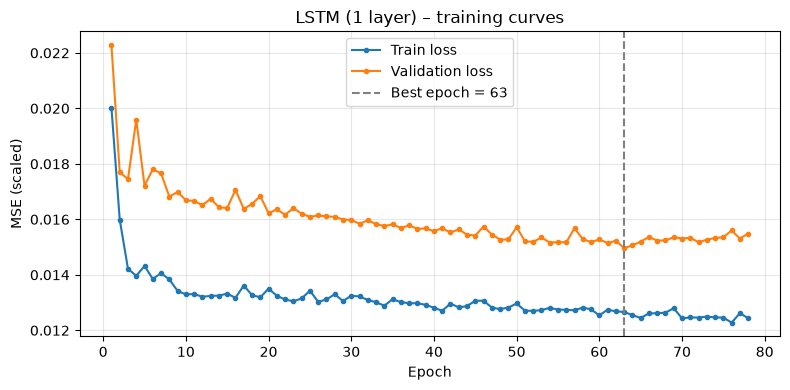

Epochs run: 78 | best epoch: 63 | training time: 12 s
Loss at epoch 1       : train 0.0200 | val 0.0223
Loss at the best epoch: train 0.0127 | val 0.0150
Loss at the last epoch: train 0.0124 | val 0.0155
Validation RMSE = 5.765 mm/day | Test RMSE = 6.158 mm/day (naive: 7.698)


In [ ]:
res_lstm = train_variant('LSTM (1 layer)', SEED)
plot_curves(res_lstm, 'LSTM (1 layer) – training curves')

h = res_lstm['history']
print(f"Epochs run: {res_lstm['epochs_run']} | best epoch: {res_lstm['best_epoch']} | training time: {res_lstm['seconds']:.0f} s")
print(f"Loss at epoch 1       : train {h['train_loss'][0]:.4f} | val {h['val_loss'][0]:.4f}")
print(f"Loss at the best epoch: train {h['train_loss'][res_lstm['best_epoch']-1]:.4f} | val {h['val_loss'][res_lstm['best_epoch']-1]:.4f}")
print(f"Loss at the last epoch: train {h['train_loss'][-1]:.4f} | val {h['val_loss'][-1]:.4f}")
print(f"Validation RMSE = {res_lstm['rmse_val']:.3f} mm/day | Test RMSE = {res_lstm['rmse_test']:.3f} mm/day (naive: {naive_rmse_test:.3f})")

In [ ]:
# Automatic reading of the training curves (Indonesian), based on the numbers above
h, be = res_lstm['history'], res_lstm['best_epoch']
tr_b, va_b = h['train_loss'][be - 1], h['val_loss'][be - 1]
stopped_early = res_lstm['epochs_run'] < MAX_EPOCHS
overfit = (h['val_loss'][-1] > va_b * 1.05) and (h['train_loss'][-1] < h['train_loss'][be - 1] * 1.02)

text = f'''**Analisis kurva pelatihan LSTM.**
Pada epoch pertama loss latih = {h['train_loss'][0]:.4f} dan loss validasi = {h['val_loss'][0]:.4f}. Kedua kurva turun paling cepat pada beberapa epoch awal lalu melandai;
loss terendah pada data validasi dicapai pada **epoch ke-{be}** (loss latih {tr_b:.4f}, loss validasi {va_b:.4f}). '''
if stopped_early:
    text += (f"Setelah epoch tersebut loss validasi tidak membaik selama {PATIENCE} epoch, sehingga *early stopping* menghentikan pelatihan pada epoch {res_lstm['epochs_run']} "
             "dan bobot terbaik dikembalikan. ")
else:
    text += (f"Pelatihan berjalan sampai batas maksimum {MAX_EPOCHS} epoch; kurva validasi sudah hampir mendatar, sehingga tambahan epoch hanya memberi perbaikan yang sangat kecil. ")
if overfit:
    text += 'Loss validasi mulai naik sementara loss latih terus turun, tanda **overfitting**. '
else:
    text += 'Loss validasi tidak naik kembali di akhir pelatihan, sehingga **tidak terlihat overfitting yang berarti**. '
text += (f"Loss validasi sedikit lebih tinggi daripada loss latih (selisih {va_b - tr_b:.4f}); hal ini wajar karena periode validasi (data yang lebih baru) tidak pernah dilihat saat pelatihan. "
         "Nilai loss tetap relatif tinggi karena curah hujan harian sangat fluktuatif dan sulit diprediksi hanya dari data harian sebelumnya.")
display(Markdown(text))

**Analisis kurva pelatihan LSTM.**
Pada epoch pertama loss latih = 0.0200 dan loss validasi = 0.0223. Kedua kurva turun paling cepat pada beberapa epoch awal lalu melandai;
loss terendah pada data validasi dicapai pada **epoch ke-63** (loss latih 0.0127, loss validasi 0.0150). Setelah epoch tersebut loss validasi tidak membaik selama 15 epoch, sehingga *early stopping* menghentikan pelatihan pada epoch 78 dan bobot terbaik dikembalikan. Loss validasi tidak naik kembali di akhir pelatihan, sehingga **tidak terlihat overfitting yang berarti**. Loss validasi sedikit lebih tinggi daripada loss latih (selisih 0.0023); hal ini wajar karena periode validasi (data yang lebih baru) tidak pernah dilihat saat pelatihan. Nilai loss tetap relatif tinggi karena curah hujan harian sangat fluktuatif dan sulit diprediksi hanya dari data harian sebelumnya.

## 4. Comparison of Three Variants

Compared under identical conditions (same data, window, optimizer, early stopping, hidden size = 64):

| Variant | Idea |
|---|---|
| **LSTM (1 layer)** | Standard LSTM with forget / input / output gates and a cell state |
| **GRU (1 layer)** | Simplified gated unit (update + reset gate, no separate cell state) → fewer parameters, faster |
| **Stacked LSTM (2 layers)** | Two LSTM layers on top of each other → can learn more abstract temporal patterns, but more parameters |

Because the result of one training run depends on the random initialisation, every variant is trained with **3 seeds** and the table reports the **mean ± standard deviation**.
The best variant is chosen with the **validation** RMSE (the test set is only used for the final report).

In [ ]:
for name in VARIANTS:
    for sd in SEEDS:
        r = train_variant(name, sd)
        print(f"{name:<25} seed {sd}: best epoch {r['best_epoch']:>2}/{r['epochs_run']:>2} | val RMSE {r['rmse_val']:.3f} | test RMSE {r['rmse_test']:.3f} | {r['seconds']:.0f}s")

LSTM (1 layer)            seed 42: best epoch 63/78 | val RMSE 5.765 | test RMSE 6.158 | 12s
LSTM (1 layer)            seed 43: best epoch 86/100 | val RMSE 5.792 | test RMSE 6.167 | 16s
LSTM (1 layer)            seed 44: best epoch 96/100 | val RMSE 5.773 | test RMSE 6.144 | 15s
GRU (1 layer)             seed 42: best epoch 86/100 | val RMSE 5.759 | test RMSE 6.216 | 14s
GRU (1 layer)             seed 43: best epoch 86/100 | val RMSE 5.838 | test RMSE 6.238 | 15s
GRU (1 layer)             seed 44: best epoch 86/100 | val RMSE 5.796 | test RMSE 6.229 | 14s
Stacked LSTM (2 layers)   seed 42: best epoch 49/64 | val RMSE 5.808 | test RMSE 6.174 | 11s
Stacked LSTM (2 layers)   seed 43: best epoch 36/51 | val RMSE 5.800 | test RMSE 6.151 | 8s
Stacked LSTM (2 layers)   seed 44: best epoch 51/66 | val RMSE 5.826 | test RMSE 6.183 | 12s


,Parameters,Best epoch (mean),Time/run (s),Val RMSE,Val MAE,Test RMSE,Test MAE
Model,,,,,,,
LSTM (1 layer),17217,81.7,14,5.777 ± 0.011,4.014 ± 0.017,6.156 ± 0.009,4.727 ± 0.016
GRU (1 layer),12929,86.0,14,5.797 ± 0.032,3.982 ± 0.007,6.228 ± 0.009,4.755 ± 0.003
Stacked LSTM (2 layers),50497,45.3,10,5.811 ± 0.011,4.011 ± 0.031,6.169 ± 0.013,4.713 ± 0.020
Naive baseline (reference),0,-,-,7.328,4.571,7.698,5.572


Best variant by validation RMSE: LSTM (1 layer)


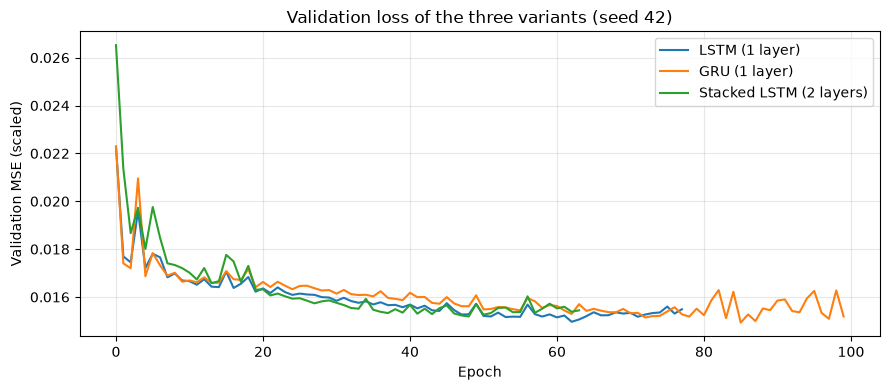

In [ ]:
rows = []
for name in VARIANTS:
    rs = [trained[(name, sd)] for sd in SEEDS]
    f = lambda key: np.array([r[key] for r in rs])
    rows.append({
        'Model': name, 'Parameters': rs[0]['params'],
        'Best epoch (mean)': round(f('best_epoch').mean(), 1), 'Time/run (s)': round(f('seconds').mean()),
        'Val RMSE': f"{f('rmse_val').mean():.3f} ± {f('rmse_val').std():.3f}",
        'Val MAE':  f"{f('mae_val').mean():.3f} ± {f('mae_val').std():.3f}",
        'Test RMSE': f"{f('rmse_test').mean():.3f} ± {f('rmse_test').std():.3f}",
        'Test MAE':  f"{f('mae_test').mean():.3f} ± {f('mae_test').std():.3f}",
        '_val_rmse': f('rmse_val').mean(), '_test_rmse': f('rmse_test').mean(), '_test_mae': f('mae_test').mean()})
comp = pd.DataFrame(rows)

ref_rows = pd.DataFrame([
    {'Model': 'Naive baseline (reference)', 'Parameters': 0, 'Best epoch (mean)': '-', 'Time/run (s)': '-',
     'Val RMSE': f"{rmse(y_true['val'], naive_pred['val']):.3f}", 'Val MAE': f"{mae(y_true['val'], naive_pred['val']):.3f}",
     'Test RMSE': f'{naive_rmse_test:.3f}', 'Test MAE': f'{naive_mae_test:.3f}'}])
display(pd.concat([comp.drop(columns=['_val_rmse', '_test_rmse', '_test_mae']), ref_rows], ignore_index=True).set_index('Model'))

best_name = comp.loc[comp['_val_rmse'].idxmin(), 'Model']
print('Best variant by validation RMSE:', best_name)

plt.figure(figsize=(9, 4))
for name in VARIANTS:
    h = trained[(name, SEED)]['history']
    plt.plot(h['val_loss'], label=name)
plt.xlabel('Epoch'); plt.ylabel('Validation MSE (scaled)'); plt.title(f'Validation loss of the three variants (seed {SEED})'); plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
# Automatic reasoning for the choice of the best model (Indonesian)
c = comp.set_index('Model')
order = c['_val_rmse'].sort_values()
b, second = order.index[0], order.index[1]
gap = (order.iloc[1] - order.iloc[0]) / order.iloc[1] * 100
consistent = all(trained[(b, sd)]['rmse_val'] < trained[(second, sd)]['rmse_val'] for sd in SEEDS)
tp = c['Parameters']

text = f'''**Pemilihan model terbaik.** Berdasarkan RMSE validasi rata-rata dari {len(SEEDS)} seed, varian terbaik adalah **{b}** (RMSE validasi {order.iloc[0]:.3f} mm/hari), diikuti {second} ({order.iloc[1]:.3f}); selisihnya {gap:.1f}%. '''
if consistent:
    text += f'{b} lebih baik daripada {second} pada **setiap seed**, sehingga keunggulannya konsisten (bukan kebetulan inisialisasi). '
else:
    text += f'Namun urutan antara {b} dan {second} tidak konsisten pada semua seed, sehingga keunggulannya belum pasti. '
if gap < 3:
    text += 'Besar keunggulannya kecil, sehingga ketiga varian pada dasarnya berkinerja hampir setara. '
text += (f"Pertimbangan lain: jumlah parameter LSTM 1 lapis = {tp['LSTM (1 layer)']:,}, GRU = {tp['GRU (1 layer)']:,}, Stacked LSTM = {tp['Stacked LSTM (2 layers)']:,}. ")
if c.loc['Stacked LSTM (2 layers)', '_val_rmse'] < c.loc['LSTM (1 layer)', '_val_rmse']:
    text += 'Stacked LSTM memberi perbaikan kecil pada data validasi, tetapi dengan parameter dan waktu latih yang jauh lebih besar. '
else:
    text += ('Penambahan kapasitas (Stacked LSTM dengan parameter hampir 3 kali lipat) tidak memperbaiki RMSE validasi, sehingga batas akurasi tampaknya '
             'ada pada informasi di dalam data (sinyal curah hujan harian yang lemah), bukan pada ukuran model. ')
best_test_name = c['_test_rmse'].idxmin()
if best_test_name == b:
    text += f"Pada data uji, {b} juga menjadi yang terbaik (RMSE {c.loc[b, '_test_rmse']:.3f} mm/hari), konsisten dengan urutan pada data validasi."
else:
    text += f"Pada data uji varian terbaik adalah {best_test_name}; perbedaan kecil seperti ini wajar karena data uji hanya 329 hari."
display(Markdown(text))

**Pemilihan model terbaik.** Berdasarkan RMSE validasi rata-rata dari 3 seed, varian terbaik adalah **LSTM (1 layer)** (RMSE validasi 5.777 mm/hari), diikuti GRU (1 layer) (5.797); selisihnya 0.4%. Namun urutan antara LSTM (1 layer) dan GRU (1 layer) tidak konsisten pada semua seed, sehingga keunggulannya belum pasti. Besar keunggulannya kecil, sehingga ketiga varian pada dasarnya berkinerja hampir setara. Pertimbangan lain: jumlah parameter LSTM 1 lapis = 17,217, GRU = 12,929, Stacked LSTM = 50,497. Penambahan kapasitas (Stacked LSTM dengan parameter hampir 3 kali lipat) tidak memperbaiki RMSE validasi, sehingga batas akurasi tampaknya ada pada informasi di dalam data (sinyal curah hujan harian yang lemah), bukan pada ukuran model. Pada data uji, LSTM (1 layer) juga menjadi yang terbaik (RMSE 6.156 mm/hari), konsisten dengan urutan pada data validasi.

## 5. Evaluation

The chosen model (seed 42) is evaluated on the **test set** (the most recent 15% of the days) with:
* **RMSE** = √(mean squared error): penalises large errors (heavy-rain days) more strongly.
* **MAE** = mean absolute error: the average error in mm/day, easy to interpret.

Both are computed in the original unit (**mm/day**), for the LSTM models and for the naive baseline on exactly the same days.

In [ ]:
best = trained[(best_name, SEED)]
final_rows = [
    ('Naive baseline (tomorrow = today)', naive_pred['test']),
    ('Train-mean reference',               mean_pred['test']),
] + [(n + ('  <- chosen' if n == best_name else ''), trained[(n, SEED)]['pred_test']) for n in VARIANTS]

final_table = pd.DataFrame([{'Model': n, 'RMSE (mm/day)': rmse(y_true['test'], p), 'MAE (mm/day)': mae(y_true['test'], p)} for n, p in final_rows]).set_index('Model')
display(final_table.round(3))

rmse_best, mae_best = best['rmse_test'], best['mae_test']
imp_rmse = (naive_rmse_test - rmse_best) / naive_rmse_test * 100
imp_mae  = (naive_mae_test - mae_best) / naive_mae_test * 100
print(f'{best_name} vs naive: RMSE {rmse_best:.3f} vs {naive_rmse_test:.3f} ({imp_rmse:+.1f}% improvement) | MAE {mae_best:.3f} vs {naive_mae_test:.3f} ({imp_mae:+.1f}% improvement)')

,RMSE (mm/day),MAE (mm/day)
Model,,
Naive baseline (tomorrow = today),7.698,5.572
Train-mean reference,6.864,5.413
LSTM (1 layer) <- chosen,6.158,4.749
GRU (1 layer),6.216,4.752
Stacked LSTM (2 layers),6.174,4.690


LSTM (1 layer) vs naive: RMSE 6.158 vs 7.698 (+20.0% improvement) | MAE 4.749 vs 5.572 (+14.8% improvement)


### 5.1 Actual vs predicted
Top: the whole test period. Bottom: a zoom on 90 days. Right: scatter plot of actual vs predicted values (the diagonal is a perfect forecast).

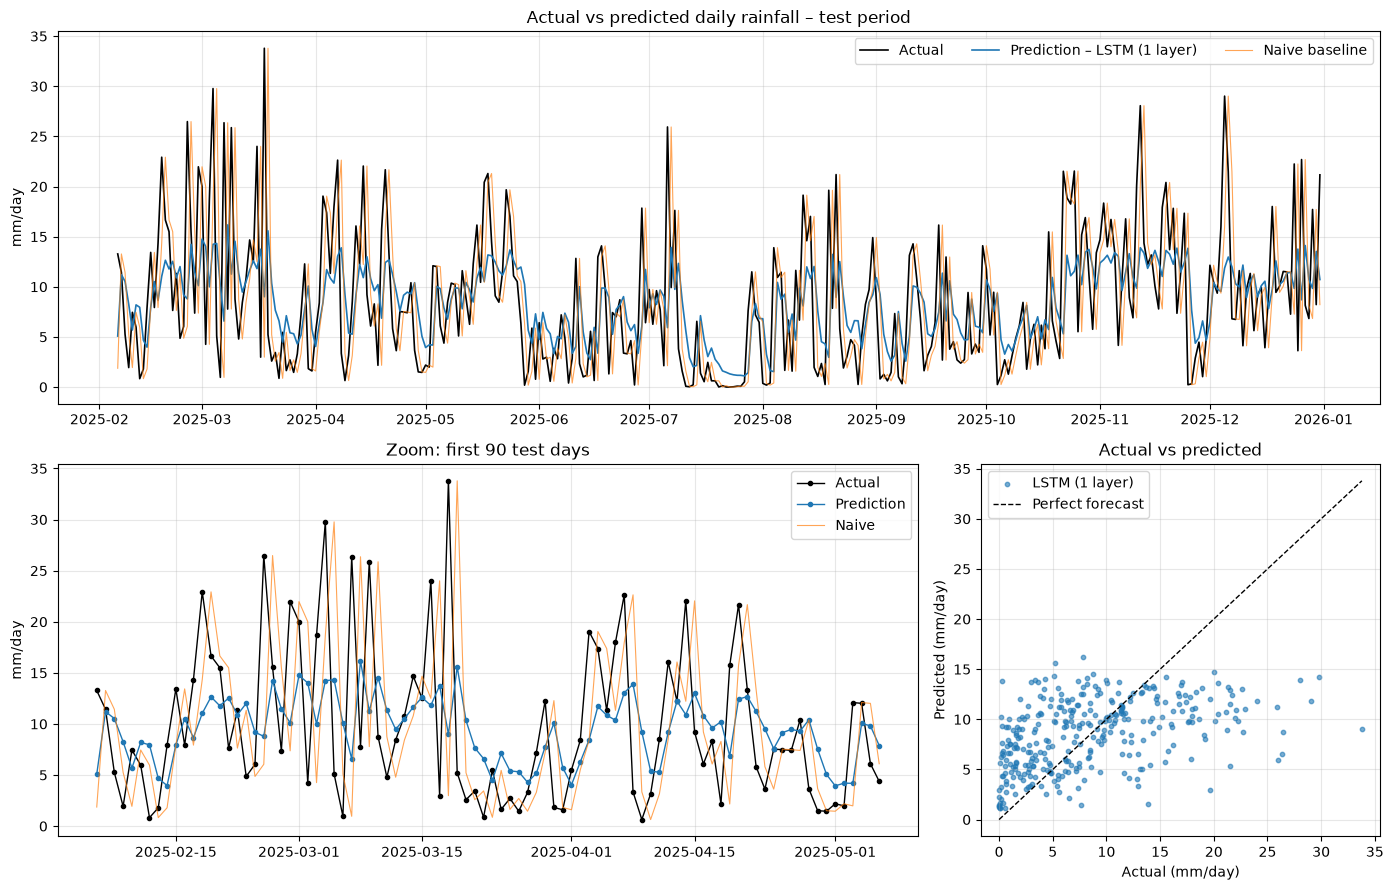

In [ ]:
dates = target_dates['test']; actual = y_true['test']
fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(2, 3)

ax = fig.add_subplot(gs[0, :])
ax.plot(dates, actual, color='black', lw=1.2, label='Actual')
ax.plot(dates, best['pred_test'], color='tab:blue', lw=1.2, label=f'Prediction – {best_name}')
ax.plot(dates, naive_pred['test'], color='tab:orange', lw=0.8, alpha=0.7, label='Naive baseline')
ax.set(title='Actual vs predicted daily rainfall – test period', ylabel='mm/day'); ax.legend(ncol=3)

z = slice(0, 90)
ax = fig.add_subplot(gs[1, :2])
ax.plot(dates[z], actual[z], color='black', marker='o', ms=3, lw=1, label='Actual')
ax.plot(dates[z], best['pred_test'][z], color='tab:blue', marker='o', ms=3, lw=1, label='Prediction')
ax.plot(dates[z], naive_pred['test'][z], color='tab:orange', lw=0.8, alpha=0.7, label='Naive')
ax.set(title='Zoom: first 90 test days', ylabel='mm/day'); ax.legend()

ax = fig.add_subplot(gs[1, 2])
ax.scatter(actual, best['pred_test'], s=10, alpha=0.6, color='tab:blue', label=best_name)
lim = max(actual.max(), best['pred_test'].max()); ax.plot([0, lim], [0, lim], 'k--', lw=1, label='Perfect forecast')
ax.set(title='Actual vs predicted', xlabel='Actual (mm/day)', ylabel='Predicted (mm/day)'); ax.legend()
plt.tight_layout(); plt.show()

### 5.2 Conclusion (Kesimpulan)
The text below is generated from the numbers computed above, so it always matches the results of the run.

In [ ]:
c = comp.set_index('Model')
mean_rmse_test = rmse(y_true['test'], mean_pred['test'])
lstm_name = 'LSTM (1 layer)'
lstm_rmse, lstm_mae = c.loc[lstm_name, '_test_rmse'], c.loc[lstm_name, '_test_mae']          # mean over seeds
lstm_imp_rmse = (naive_rmse_test - lstm_rmse) / naive_rmse_test * 100
lstm_imp_mae  = (naive_mae_test - lstm_mae) / naive_mae_test * 100
all_beat = all(trained[(n, sd)]['rmse_test'] < naive_rmse_test and trained[(n, sd)]['mae_test'] < naive_mae_test for n in VARIANTS for sd in SEEDS)
corr = np.corrcoef(actual, best['pred_test'])[0, 1]
pred = best['pred_test']
beats_mean = 'mengalahkan' if rmse_best < mean_rmse_test else 'belum mengalahkan'

paras = []
same_model = (best_name == lstm_name)
para_a = (f'''**a) Baseline vs LSTM.** Pada data uji ({len(actual)} hari, {dates[0].date()} s.d. {dates[-1].date()}), baseline naif (nilai besok = nilai hari ini) menghasilkan RMSE = {naive_rmse_test:.3f} mm/hari dan MAE = {naive_mae_test:.3f} mm/hari.
LSTM satu lapis (rata-rata {len(SEEDS)} seed) menghasilkan RMSE = {lstm_rmse:.3f} dan MAE = {lstm_mae:.3f} mm/hari, yaitu perbaikan **{lstm_imp_rmse:.1f}%** pada RMSE dan **{lstm_imp_mae:.1f}%** pada MAE.''')
if same_model:
    para_a += f''' Model ini juga yang terpilih sebagai terbaik pada data validasi; dengan seed {SEED} ia menghasilkan RMSE = {rmse_best:.3f} dan MAE = {mae_best:.3f} mm/hari.'''
else:
    para_a += f'''
Model terbaik pilihan validasi (**{best_name}**) menghasilkan RMSE = {rmse_best:.3f} dan MAE = {mae_best:.3f} mm/hari (perbaikan {imp_rmse:.1f}% dan {imp_mae:.1f}%).'''
paras.append(para_a)

if lstm_imp_rmse > 0 and lstm_imp_mae > 0:
    consist = ('Ketiga varian (LSTM, GRU, Stacked LSTM) pada seluruh seed juga mengalahkan baseline, sehingga keunggulan ini konsisten dan bukan kebetulan satu kali pelatihan. ' if all_beat
               else 'Namun tidak semua varian/seed mengalahkan baseline pada kedua metrik, sehingga keunggulannya belum sepenuhnya konsisten. ')
    paras.append('**b) Kesimpulan utama.** **Ya, LSTM lebih baik daripada baseline naif** pada kedua metrik (RMSE dan MAE). ' + consist +
                 'Selisih antar-varian (LSTM, GRU, Stacked LSTM) jauh lebih kecil daripada selisih terhadap baseline.')
else:
    paras.append(f'**b) Kesimpulan utama.** LSTM **tidak lebih baik** daripada baseline naif pada kedua metrik (RMSE {lstm_rmse:.3f} vs {naive_rmse_test:.3f}; MAE {lstm_mae:.3f} vs {naive_mae_test:.3f}).')

paras.append(f'''**c) Konteks dan pembacaan grafik.** Prediksi curah hujan harian sangat sulit karena hujan sangat bervariasi dari hari ke hari (autokorelasi lag-1 hanya {acf[0]:.2f}).
Baseline naif lemah di sini karena nilai kemarin hanya berkorelasi sedang dengan hari ini: setiap lonjakan atau penurunan tiba-tiba membuat prediksinya tertinggal satu hari dan menghasilkan kesalahan ganda (pada grafik, garis oranye selalu terlambat satu hari).
Sebagai pembanding, prediksi konstan berupa rata-rata data latih memiliki RMSE {mean_rmse_test:.3f} mm/hari; model {beats_mean} acuan ini.
Korelasi aktual vs prediksi pada data uji = {corr:.2f}. Prediksi model jauh lebih halus daripada data aktual (simpangan baku prediksi {pred.std():.2f} vs aktual {actual.std():.2f} mm/hari; nilai maksimum prediksi {pred.max():.1f} vs aktual {actual.max():.1f} mm/hari),
sehingga model menangkap pola umum (tren musim basah/kering) tetapi **tidak mampu memprediksi hari-hari hujan ekstrem**. Hal ini wajar karena MSE mendorong model memilih nilai aman di sekitar rata-rata ketika sinyalnya lemah.''')

paras.append('''**d) Keterbatasan dan saran.** (1) Model hanya memakai riwayat curah hujan; menambahkan fitur kalender (bulan atau hari dalam setahun) atau variabel cuaca lain (kelembapan, suhu) kemungkinan besar meningkatkan akurasi.
(2) Target adalah rata-rata seluruh stasiun, sehingga variasi antar-wilayah hilang. (3) Selisih antar-varian yang kecil tidak boleh dianggap pasti karena data uji hanya satu periode (329 hari) dan jumlah seed terbatas.
(4) Untuk kejadian hujan ekstrem diperlukan fungsi loss atau model yang menekankan nilai besar, serta horizon prediksi yang sesuai kebutuhan.''')
display(Markdown('\n\n'.join(paras)))

**a) Baseline vs LSTM.** Pada data uji (329 hari, 2025-02-06 s.d. 2025-12-31), baseline naif (nilai besok = nilai hari ini) menghasilkan RMSE = 7.698 mm/hari dan MAE = 5.572 mm/hari.
LSTM satu lapis (rata-rata 3 seed) menghasilkan RMSE = 6.156 dan MAE = 4.727 mm/hari, yaitu perbaikan **20.0%** pada RMSE dan **15.2%** pada MAE. Model ini juga yang terpilih sebagai terbaik pada data validasi; dengan seed 42 ia menghasilkan RMSE = 6.158 dan MAE = 4.749 mm/hari.

**b) Kesimpulan utama.** **Ya, LSTM lebih baik daripada baseline naif** pada kedua metrik (RMSE dan MAE). Ketiga varian (LSTM, GRU, Stacked LSTM) pada seluruh seed juga mengalahkan baseline, sehingga keunggulan ini konsisten dan bukan kebetulan satu kali pelatihan. Selisih antar-varian (LSTM, GRU, Stacked LSTM) jauh lebih kecil daripada selisih terhadap baseline.

**c) Konteks dan pembacaan grafik.** Prediksi curah hujan harian sangat sulit karena hujan sangat bervariasi dari hari ke hari (autokorelasi lag-1 hanya 0.49).
Baseline naif lemah di sini karena nilai kemarin hanya berkorelasi sedang dengan hari ini: setiap lonjakan atau penurunan tiba-tiba membuat prediksinya tertinggal satu hari dan menghasilkan kesalahan ganda (pada grafik, garis oranye selalu terlambat satu hari).
Sebagai pembanding, prediksi konstan berupa rata-rata data latih memiliki RMSE 6.864 mm/hari; model mengalahkan acuan ini.
Korelasi aktual vs prediksi pada data uji = 0.43. Prediksi model jauh lebih halus daripada data aktual (simpangan baku prediksi 3.42 vs aktual 6.81 mm/hari; nilai maksimum prediksi 16.2 vs aktual 33.8 mm/hari),
sehingga model menangkap pola umum (tren musim basah/kering) tetapi **tidak mampu memprediksi hari-hari hujan ekstrem**. Hal ini wajar karena MSE mendorong model memilih nilai aman di sekitar rata-rata ketika sinyalnya lemah.

**d) Keterbatasan dan saran.** (1) Model hanya memakai riwayat curah hujan; menambahkan fitur kalender (bulan atau hari dalam setahun) atau variabel cuaca lain (kelembapan, suhu) kemungkinan besar meningkatkan akurasi.
(2) Target adalah rata-rata seluruh stasiun, sehingga variasi antar-wilayah hilang. (3) Selisih antar-varian yang kecil tidak boleh dianggap pasti karena data uji hanya satu periode (329 hari) dan jumlah seed terbatas.
(4) Untuk kejadian hujan ekstrem diperlukan fungsi loss atau model yang menekankan nilai besar, serta horizon prediksi yang sesuai kebutuhan.